# Módulo 2 — Tendência e sazonalidade

## Seção 3 — Modelagem da sazonalidade por indicadores e funções harmônicas

**Estado editorial:** primeira versão para estudo e revisão.  
**Pré-requisitos:** Seção 2 (sazonalidade e período sazonal); média, soma de quadrados, funções seno e cosseno; noções da Seção 1 sobre mínimos quadrados.  
**Base bibliográfica:** Morettin e Toloi, *Análise de Séries Temporais: Modelos lineares univariados*, vol. 1, 3ª ed., cap. 3, §3.3 (sazonalidade determinística, incluindo regressão); mapeamento das videoaulas, bloco C, aulas 33–39 (mínimos quadrados e sazonalidade). As deduções, os dados numéricos e o código abaixo constituem **complementação didática original**. A indicação bibliográfica é de localização temática; não se afirma que os exemplos originais sejam do livro ou das aulas.

### Objetivos

Ao final, você deverá conseguir: (i) representar sazonalidade com variáveis indicadoras; (ii) entender por que precisamos de uma restrição de identificação; (iii) estimar as médias sazonais por mínimos quadrados; (iv) construir uma representação por seno e cosseno; (v) explicar por que uma única harmônica pode ser insuficiente; e (vi) implementar e comparar os ajustes em Python.

### 1. O problema de modelagem

Na seção anterior, usamos o modelo aditivo

$$
Z_t=\mu+S_t+\varepsilon_t,\qquad S_{t+s}=S_t,
$$

em que $s$ é o número de observações por ciclo. Dizer que $S_t$ é periódico ainda não esclarece **como estimar** o efeito sazonal a partir de dados. Estudaremos duas formas de transformar essa ideia em um modelo computável: uma que atribui um efeito próprio a cada estação e outra que combina ondas periódicas.

Como exemplo, usaremos **dados sintéticos trimestrais** (sem tendência), observados durante três anos. Os valores, por trimestre, são

| Ano | T1 | T2 | T3 | T4 |
|---|---:|---:|---:|---:|
| 1 | 16 | 20 | 23 | 17 |
| 2 | 17 | 21 | 24 | 18 |
| 3 | 18 | 22 | 25 | 19 |

O pequeno crescimento de ano para ano nesta tabela foi construído apenas para gerar desvios em torno das médias sazonais. **Não interpretaremos esses dados inventados como evidência de tendência real.**

### 2. Modelo de indicadores (variáveis *dummy*)

Defina, para cada trimestre $j=1,2,3,4$,

$$
D_{j,t}=\begin{cases}
1,&\text{se o instante }t\text{ pertence ao trimestre }j,\\
0,&\text{caso contrário.}
\end{cases}
$$

Uma parametrização direta, sem intercepto, é

$$
\boxed{Z_t=m_1D_{1,t}+m_2D_{2,t}+m_3D_{3,t}+m_4D_{4,t}+\varepsilon_t.}
$$

Se $E[\varepsilon_t]=0$, a esperança condicional ao índice temporal do trimestre $j$ é simplesmente $m_j$. O modelo estima quatro médias, uma para cada posição do ciclo. Por exemplo, no trimestre 2, $D_{2,t}=1$ e as demais indicadoras são zero; logo, $E[Z_t]=m_2$.

**Por que não acrescentar um intercepto junto de todas as quatro indicadoras?** Porque, para todo $t$,

$$
D_{1,t}+D_{2,t}+D_{3,t}+D_{4,t}=1.
$$

A coluna de uns do intercepto seria igual à soma das quatro colunas indicadoras. Portanto, as colunas da matriz de regressão seriam linearmente dependentes e os cinco coeficientes não seriam identificáveis individualmente. Chamamos isso de **multicolinearidade perfeita**.

Há duas parametrizações equivalentes, desde que se escolham as restrições adequadas:

- **Sem intercepto e com quatro indicadoras:** cada coeficiente é a média de uma estação.
- **Com intercepto e três indicadoras:** escolhemos um trimestre como referência; o intercepto é sua média e os demais coeficientes são diferenças em relação a ela.

Também poderíamos usar um intercepto $\mu$ e quatro efeitos $S_j$ impondo $\sum_{j=1}^4 S_j=0$. Com quantidades iguais de observações por trimestre, $\mu$ é a média das quatro médias sazonais. Essa restrição é uma **convenção de identificação**, não uma exigência de que qualquer sequência periódica tenha soma zero antes da parametrização.

### 3. Por que mínimos quadrados produz médias por trimestre?

Com quatro indicadores sem intercepto, minimizamos

$$
Q(m_1,m_2,m_3,m_4)=\sum_{j=1}^{4}\sum_{t\in I_j}(z_t-m_j)^2,
$$

em que $I_j$ reúne os instantes do trimestre $j$ e $n_j=|I_j|$ conta suas observações. Para um trimestre fixo, derivamos:

$$
\frac{\partial Q}{\partial m_j}=-2\sum_{t\in I_j}(z_t-m_j).
$$

Igualando a zero,

$$
\sum_{t\in I_j}z_t-n_jm_j=0
\quad\Longrightarrow\quad
\boxed{\widehat m_j=\frac{1}{n_j}\sum_{t\in I_j}z_t.}
$$

A segunda derivada é $2n_j>0$ quando o trimestre tem observações; portanto, é um mínimo. Assim, o ajuste de indicadores por mínimos quadrados é exatamente o cálculo de uma média amostral para cada trimestre.

No exemplo:

$$
\begin{aligned}
\widehat m_1&=(16+17+18)/3=17,\\
\widehat m_2&=(20+21+22)/3=21,\\
\widehat m_3&=(23+24+25)/3=24,\\
\widehat m_4&=(17+18+19)/3=18.
\end{aligned}
$$

A média geral das quatro médias é $\widehat\mu=(17+21+24+18)/4=20$. Portanto, os efeitos sazonais com soma zero são

$$
(\widehat S_1,\widehat S_2,\widehat S_3,\widehat S_4)=(-3,1,4,-2),
$$

com $-3+1+4-2=0$.

**Hipóteses e alcance:** a identidade de mínimos quadrados acima é puramente algébrica. Para interpretar os coeficientes como estimadores de médias de um mecanismo probabilístico, precisamos acrescentar hipóteses sobre a média dos erros. Para inferência clássica (erros-padrão, testes e intervalos), exigem-se condições adicionais sobre dependência, heterocedasticidade e/ou distribuição. A repetição observada não demonstra que o mecanismo sazonal seja imutável no futuro.

### 4. Harmônicas: outra linguagem para periodicidade

Uma oscilação periódica de período $s$ pode ser descrita por funções trigonométricas. Uma componente harmônica de frequência $k/s$ ciclos por observação é

$$
H_{k,t}=a_k\cos\left(\frac{2\pi k t}{s}\right)+b_k\sin\left(\frac{2\pi k t}{s}\right).
$$

- $t$: índice da observação;
- $s$: período sazonal;
- $k$: número da harmônica (1, 2, ...);
- $a_k,b_k$: coeficientes reais que determinam a forma e a fase do padrão.

Por que ela se repete? Ao substituir $t$ por $t+s$, o argumento do cosseno e do seno aumenta $2\pi k$. Como $\sin(x+2\pi k)=\sin(x)$ e $\cos(x+2\pi k)=\cos(x)$, segue $H_{k,t+s}=H_{k,t}$.

Para uma única harmônica, também podemos usar a forma amplitude-fase:

$$
a_1\cos(\omega t)+b_1\sin(\omega t)
=A\cos(\omega t-\varphi),
$$

em que $\omega=2\pi/s$, $A=\sqrt{a_1^2+b_1^2}$ e $\varphi=\mathrm{atan2}(b_1,a_1)$. Isso segue de $\cos(x-\varphi)=\cos x\cos\varphi+\sin x\sin\varphi$.

Um modelo inicial de sazonalidade harmônica é

$$
\boxed{Z_t=\mu+a_1\cos(2\pi t/s)+b_1\sin(2\pi t/s)+\varepsilon_t.}
$$

Seu principal benefício é **economia de parâmetros**, mas ele não consegue representar qualquer conjunto de médias sazonais quando $s$ é maior que três.

### 5. Por que a primeira harmônica não representa todo padrão trimestral?

No caso trimestral, $s=4$. A frequência fundamental é $1/4$ ciclo por observação. Um modelo com intercepto, seno e cosseno da primeira harmônica possui apenas três parâmetros. Já quatro médias trimestrais arbitrárias correspondem a quatro graus de liberdade. Falta uma direção para reproduzir qualquer padrão.

Para quatro trimestres, o modelo harmônico completo inclui a componente de frequência $2/4=1/2$:

$$
\boxed{
Z_t=\mu+a_1\cos(\pi t/2)+b_1\sin(\pi t/2)
+a_2\cos(\pi t)+\varepsilon_t.
}
$$

O termo $\sin(\pi t)$ é identicamente zero quando $t$ é inteiro; por isso não entra no modelo. O termo $\cos(\pi t)=(-1)^t$ permite capturar a alternância adicional que falta à primeira harmônica. Com quatro trimestres observados, essas quatro colunas são linearmente independentes e podem representar qualquer padrão fixo de quatro médias trimestrais.

**Cuidado:** “harmônica completa” não significa que as observações serão reproduzidas exatamente. Significa que podemos reproduzir **as quatro médias por trimestre**; o ruído residual entre anos permanece.

### 6. Implementação em Python — do cálculo manual ao ajuste matricial

O código a seguir é **autossuficiente** e produz o gráfico comparativo. Requer Python 3, NumPy e Matplotlib. Os dados são inteiramente sintéticos, fixados no próprio script; portanto não há aleatoriedade nem necessidade de semente neste experimento.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 12 observações trimestrais (3 anos), em ordem cronológica.
z = np.array([16, 20, 23, 17,
              17, 21, 24, 18,
              18, 22, 25, 19], dtype=float)
n = len(z)
t = np.arange(1, n + 1)  # instantes 1, 2, ..., 12
s = 4                       # observações por ciclo

# Para t=1,2,3,4,5,..., os trimestres são 0,1,2,3,0,...
trimestre = (t - 1) % s

# Nível 1: estimar cada média diretamente.
medias = np.array([z[trimestre == j].mean() for j in range(s)])
ajuste_indicadores = medias[trimestre]

# Nível 2: construir a matriz das quatro indicadoras e resolver MQO.
D = (trimestre[:, None] == np.arange(s)[None, :]).astype(float)
coeficientes, *_ = np.linalg.lstsq(D, z, rcond=None)
assert np.allclose(coeficientes, medias)

# Harmônica fundamental: intercepto, cosseno e seno.
omega = 2 * np.pi / s
X1 = np.column_stack([np.ones(n),
                      np.cos(omega * t), np.sin(omega * t)])
beta1, *_ = np.linalg.lstsq(X1, z, rcond=None)
ajuste_h1 = X1 @ beta1

# Harmônica completa para s=4: acrescentar cos(pi*t).
X2 = np.column_stack([X1, np.cos(np.pi * t)])
beta2, *_ = np.linalg.lstsq(X2, z, rcond=None)
ajuste_h2 = X2 @ beta2

# Verificar que os modelos saturados estimam as mesmas médias sazonais.
assert np.allclose(ajuste_indicadores, ajuste_h2)

print('Médias sazonais:', medias)
print('Efeitos de soma zero:', medias - medias.mean())
print('MQE indicadoras:', np.mean((z - ajuste_indicadores)**2))
print('MQE harmônica 1:', np.mean((z - ajuste_h1)**2))
print('MQE harmônica completa:', np.mean((z - ajuste_h2)**2))

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(t, z, 'o-', label='Dados sintéticos')
axes[0].plot(t, ajuste_indicadores, 's--', label='Médias sazonais')
axes[0].set_ylabel('Valor')
axes[0].set_title('Ajuste por indicadores trimestrais')
axes[0].legend()

axes[1].plot(t, z, 'o-', alpha=.65, label='Dados sintéticos')
axes[1].plot(t, ajuste_h1, '--', label='1ª harmônica')
axes[1].plot(t, ajuste_h2, 's-', label='Harmônica completa')
axes[1].set_xlabel('Trimestre observado (t)')
axes[1].set_ylabel('Valor')
axes[1].set_title('Ajuste por funções harmônicas')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=.25)
fig.tight_layout()
plt.show()


**Por que essas funções?** `np.array` cria um vetor numérico; `np.arange` cria índices; `%` calcula o resto e identifica a estação; `np.mean` obtém médias; `np.column_stack` agrupa as colunas da matriz de regressão; `np.linalg.lstsq(X, z, rcond=None)` encontra o vetor $\widehat\beta$ que minimiza $\|X\beta-z\|_2^2$, mesmo sem inverter $X^TX$ explicitamente; `@` implementa a multiplicação matricial. As funções `plot`, `legend` e `grid` produzem e identificam os gráficos.

**Atenção:** as matrizes representam amostras *nas linhas* e variáveis explicativas *nas colunas*. O formato de `D` é (12, 4), `X1` é (12, 3) e `X2` é (12, 4). No caso de dados ausentes, construir trimestres com `(t - 1) % 4` só é apropriado se os índices temporais representarem efetivamente trimestres consecutivos; para dados reais, devemos usar datas e verificar ausências e regularidade.

### 7. Resultado e interpretação

O cálculo produz:

| Modelo | Número de coeficientes | Erro quadrático médio no conjunto utilizado |
|---|---:|---:|
| Indicadoras trimestrais | 4 | 2/3 ≈ 0,6667 |
| Primeira harmônica | 3 | 11/12 ≈ 0,9167 |
| Harmônica completa (s=4) | 4 | 2/3 ≈ 0,6667 |

O padrão trimestral estimado é $(17,21,24,18)$, e a diferença entre os erros dos dois modelos harmônicos decorre da limitação da primeira harmônica em reproduzir quatro níveis arbitrários. O modelo completo coincide com o de indicadoras **nos valores ajustados**, não necessariamente em seus coeficientes, porque usam bases diferentes para o mesmo espaço de funções trimestrais.

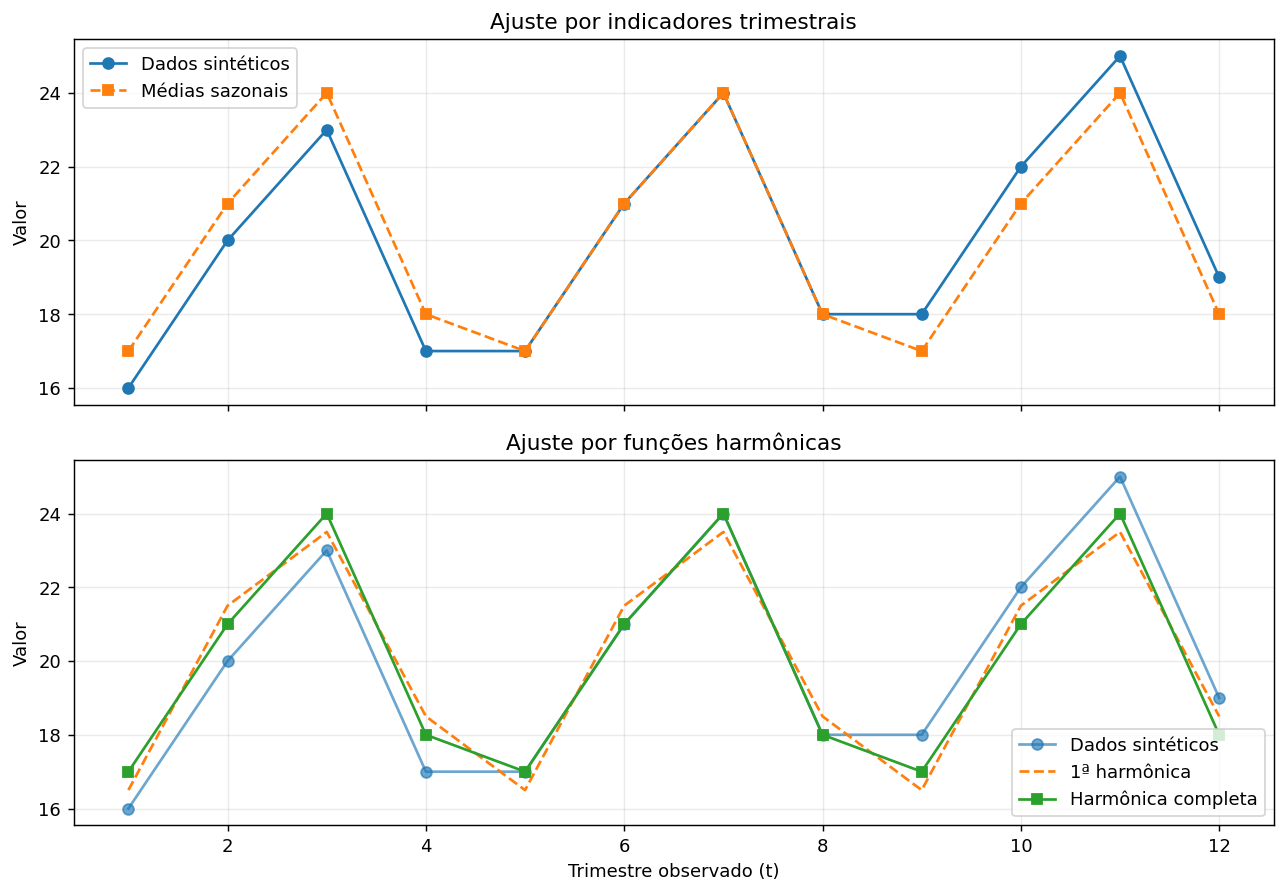

**Figura 1 —** No painel superior, as médias por trimestre reproduzem o padrão sazonal médio dos dados sintéticos. No painel inferior, a primeira harmônica suaviza esse padrão; ao acrescentar a segunda frequência permitida para quatro observações por ciclo, o ajuste harmônico reproduz as mesmas médias trimestrais do modelo de indicadores. O gráfico não permite inferir significância estatística, estabilidade futura ou qualidade preditiva fora da amostra.

### 8. Limitações e cuidados

1. Indicadores exigem observações suficientes em cada estação. Se uma estação não foi observada, sua média não pode ser estimada diretamente.
2. Padrão trimestral fixo é uma hipótese simplificadora: efeitos sazonais reais podem variar ao longo do tempo.
3. Harmônicas com menos parâmetros impõem suavidade e podem subajustar padrões irregulares; aumentar termos pode causar sobreajuste quando existem poucos dados.
4. Mínimos quadrados minimiza erro no conjunto ajustado, mas isso não garante bons resultados futuros.
5. Comparar modelos no mesmo conjunto usado para estimação é uma análise **descritiva**, não uma validação preditiva. A avaliação futura exigirá separação cronológica.
6. Não interpretamos resíduos correlacionados como ruído independente sem examinar suas propriedades. ACF e diagnóstico de resíduos serão estudados posteriormente.

### 9. Exercícios (para resolver antes de consultar uma implementação pronta)

**1 — Cálculo manual.** Suponha dois anos de dados trimestrais: ano 1 = (9, 12, 15, 10) e ano 2 = (11, 14, 17, 12). Calcule as quatro médias sazonais e os quatro efeitos com soma zero.

**2 — Identificação.** Explique por que a matriz de regressão com intercepto e quatro indicadores trimestrais não tem posto completo. Qual coluna você poderia retirar sem perder a capacidade de representar as quatro médias?

**3 — Programação.** Modifique o código para representar os dados do exercício 1, sem alterar a lógica do algoritmo. Compare os modelos de indicadores e harmônico completo.

**4 — Interpretação.** Se duas séries trimestrais possuem a mesma média global, isso implica que possuem o mesmo padrão sazonal? Justifique com um contraexemplo numérico.

### 10. Síntese

A sazonalidade determinística pode ser parametrizada por níveis fixos de cada estação ou por componentes periódicas de seno e cosseno. Indicadores tornam as médias por estação diretamente interpretáveis; harmônicas organizam o mesmo fenômeno por frequências. Ambas são formas de regressão linear nos **parâmetros**, embora seno e cosseno sejam funções não lineares do índice temporal. A escolha depende da flexibilidade desejada, do número de observações e da finalidade da análise.

**Fontes e limites de atribuição:** Morettin e Toloi, cap. 3, §3.3, como referência temática de sazonalidade determinística; catálogo `mapeamento-conteudos-series-temporais.md`, bloco C (aulas de mínimos quadrados para sazonalidade). A tabela numérica, as deduções detalhadas, as comparações de parametrizações e a implementação são desenvolvimento didático original desta seção.